# Hydra crash course

METIS is configured end-to-end with the [Hydra](https://hydra.cc). You
don’t need to touch Python to change models, datasets or training
settings — you compose and override Hydra configs instead.

## Hydra basics

Hydra’s configuration files are simple text-based
[YAML](https://yaml.org/about/) files. For example a basic training
config might look like this:

``` yaml
data: malaria_data
model: transformer
steps: 10000
```

Once ingested into a Python program (omitted here) the config’s values
can be accessed like any object:

``` python
print(config.steps) #should print 10000
```

Importantly, an entry’s value doesn’t have to just be a string or a
number, it can refer to *another* configuration file. For example, we
could create a configuration file for each dataset that stores where the
data lives and other metadata like the column names.

``` text
├── configs/
│   ├── config.yaml
│   ├── data
│       ├── malaria_data.yaml
│       └── ebola_data.yaml
│   
└── my_program.py
```

Then `malaria_data.yaml` might contain something like

``` yaml
data_path: datasets/malaria_simulations.parquet
column_names:
 - a
 - b
 - c
```

Then to get Hydra to use this config instead of a string we use the
`defaults` list directive:

``` yaml
defaults:
  data: malaria_data

model: transformer
steps: 10000
```

`defaults` is a special directive telling Hydra to use
`data/malaria_data.yaml` when composing the configuration object. The
resulting object is a composition of configs from defaults with configs
specified in your `config.yaml`.

Furthermore, when running our program in the commandline, we can
override configs or values without modifying the config file itself:

``` bash
uv run my_program --config-name config data=ebola_data steps=5000
```

Finally, overrides can happen inside configs themselves, for example, a
particular training run might fetch the data from a different location
but still have the same column names as the default `malaria_data.yaml`:

``` yaml
defaults:
  - data: malaria_data #start off with the usual values in malaria_data.yaml
  - _self_ #apply overrides in this config last 

data:
  data_path: new_location #override the data config's data_path
model: transformer
steps: 10000
```

These core features allow us to keep our configuration files nicely
structured and make it quick to try different models or datasets.

> **Tip**
>
> Hydra has many more features not mentioned here. If you ever get stuck
> or feel a bit lost the [Hydra
> tutorials](https://hydra.cc/docs/tutorials/intro/) are excellent and
> most LLMs are helpful when writing or editing Hydra configs.

## Writing a config for our data

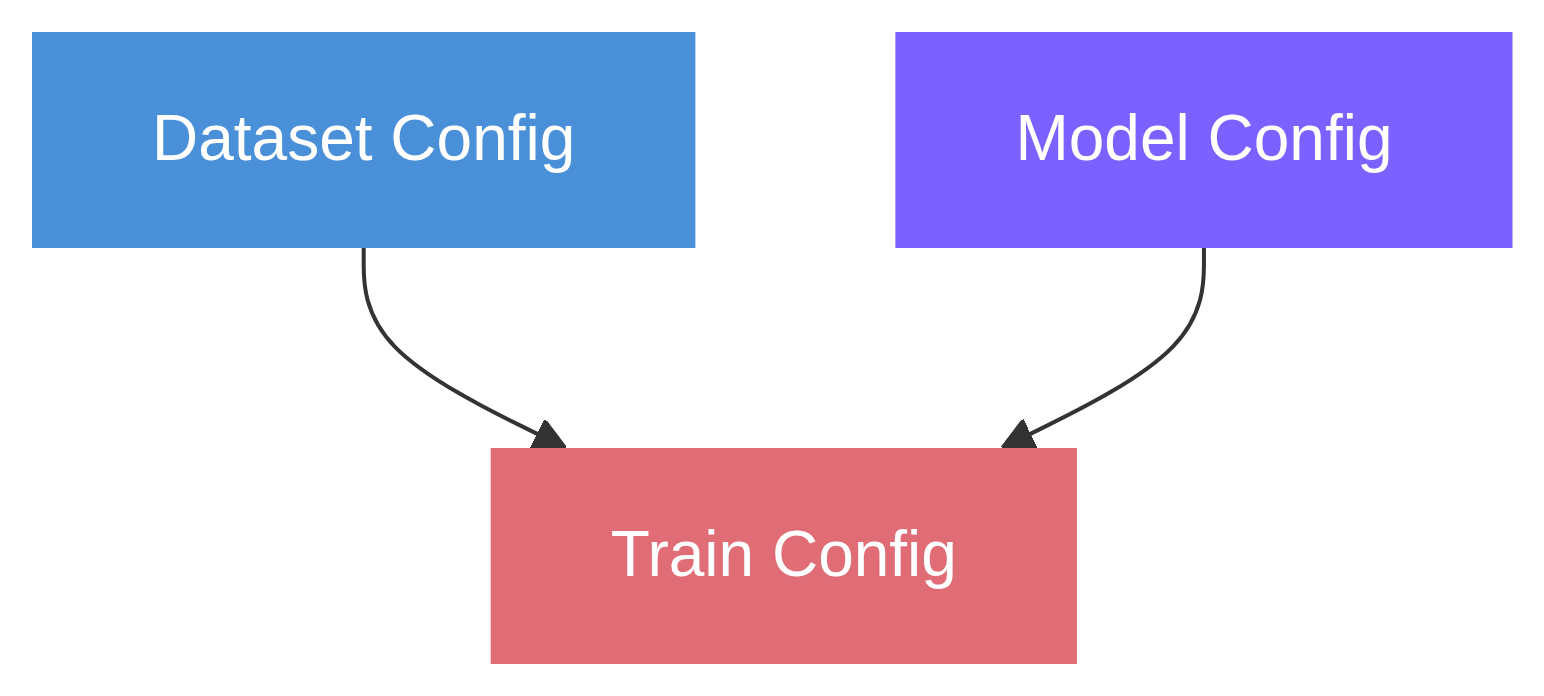

The config system in Metis is quite similar to the examples we had
above, a train config is composed out of a model config and a dataset
config. For a quickstart we’ll just focus on the dataset config since we
can simply override existing training configs to use it.

Here’s the completed config for our example SIRDS dataset. It’s fairly
self-explanatory, `surrogate_input_variables` are *static* input values
that we’d like our surrogate to condition on and `output_variables` are
what we’d like the surrogate to predict. `grouping_variables` are used
to group `reps` together, for most use-cases `grouping_variables` should
be the same as the `surrogate_inputs`, but for some datasets this
flexibility is needed.

``` yaml
surrogate_input_variables:
  - I_0
  - beta
  - gamma
  - omega
  - mu

grouping_variables:
  - I_0
  - beta
  - gamma
  - omega
  - mu 

output_variables:
  - S_t
  - I_t
  - R_t
  - D_t

num_timesteps: 200
path: examples/sirds_data.parquet

# advanced options we'll ignore for now
trunc_until: null
input_col_to_source_col: null
observed_output_variables: null
exclude_output_variables: null
```

Save this config as `sirds.yaml` in `configs/dataset`, we’ll need it for
a tutorial on training.

> **Important**
>
> Later on we’ll explore some of the other options, including
> conditioning on inputs that vary in time.